# M01-1 | 最小 PTQ：四個步驟

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m01_hello_pt2e/01_minimal_ptq.ipynb)

這本 notebook 把一個訓練好的小模型走完 PT2E 的 post-training quantization（PTQ）：

| 步驟 | API | 對圖做了什麼 |
|---|---|---|
| 1. export | `torch.export.export` | 把 `nn.Module` 變成 ATen op 組成的 fx 圖 |
| 2. prepare | `prepare_pt2e(圖, quantizer)` | 依 quantizer 的標註，在要量化的邊上插 observer |
| 3. calibrate | 直接呼叫圖 | 餵代表性資料，observer 記下 min/max |
| 4. convert | `convert_pt2e(圖)` | 把 observer 換成 quantize / dequantize node |

每一步之後都畫出**同一塊局部**（模型最前面的 conv → bn → relu → max_pool2d），看它怎麼變。
由上往下逐格執行即可。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m01_hello_pt2e")

In [1]:
import copy

import torch

from common.data import calibration_batches, evaluate, make_loader, train
from common.graph_utils import compare, observer_nodes, qdq_nodes, short, sqnr
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## 0. 先訓練一個堪用的 fp32 模型

`TinyConvNet` 是本專案的小分類網路（conv-bn-relu、一個 residual block、linear），
資料是合成的 4 類圖片，不用下載。訓練幾個 epoch 就有八成以上的 accuracy，量化前後才有東西可比。

In [2]:
model = get_model("tiny")
train_loader = make_loader(2048, seed=0)
test_loader = make_loader(512, seed=7, shuffle=False)
train(model, train_loader, epochs=6, lr=0.05)
model.eval()
acc_fp32 = evaluate(model, test_loader)
print(f"fp32 accuracy = {acc_fp32:.4f}")

fp32 accuracy = 0.8828


## 1. export：把模型變成圖

`export_module()` 底下呼叫 `torch.export.export(model, example_inputs)`，並把 batch 維度設成動態
（校準時會餵不同的 batch size）。得到的是 `GraphModule`：每個 node 是一個 ATen op。

先把圖上的運算依序列成一行，當作地圖：

In [3]:
ex = example_inputs()
gm = export_module(model, ex)
print(" → ".join(short(n.target) for n in gm.graph.nodes if n.op == "call_function"))

conv2d → batch_norm → relu → max_pool2d → conv2d → batch_norm → relu → conv2d → batch_norm → add → relu → max_pool2d → conv2d → batch_norm → relu → adaptive_avg_pool2d → flatten → linear


之後只畫最前面這一段。`draw()` 的 `focus` 指定要看的 node，`hops=0` 表示不再往外擴張；
虛線的「…」代表圖上還有別的 node 接在這裡，只是沒畫出來。
weight、bias 這類參數不另外畫，寫在使用它的 op 底下的 `‹…›` 裡。

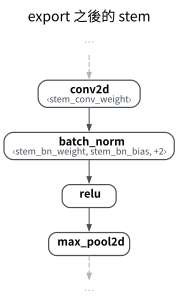

In [4]:
STEM = ["conv2d", "batch_norm", "relu", "max_pool2d"]
draw(gm, focus=STEM, hops=0, title="export 之後的 stem")

## 2. prepare：依標註插 observer

`quantizer` 決定「哪條邊要量化、用什麼規格」。它本身不量化任何東西，只在 `node.meta` 上貼標註；
`prepare_pt2e` 讀這些標註，在對應的邊上插 observer。
這裡用 XNNPACK 的 quantizer（`is_per_channel=True`：weight 每個 output channel 一組 scale）。

注意 `prepare_pt2e` 會**原地修改**傳進去的圖，回傳的也是同一個物件。
這裡想保留 export 的圖來對照，所以先 `copy.deepcopy`。

In [5]:
quantizer, src = get_xnnpack_quantizer(is_per_channel=True)
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
assert prepared is not gm
print(f"XNNPACKQuantizer 來源：{src}")
print(f"插入的 observer 數量：{len(observer_nodes(prepared))}")

XNNPACKQuantizer 來源：torchao.testing
插入的 observer 數量：16


左邊是 export 的圖，右邊是 `prepare_pt2e` 之後。請看三件事：

- `batch_norm` 不見了：它在 prepare 時被折進 conv 的 weight 和 bias（M04 細講）。
- conv 的 weight 前面多了 `PerChannelMinMaxObserver`，activation 的邊上多了 `HistogramObserver`。
- conv 和 relu **之間沒有** observer：quantizer 把 conv + relu 當成一組，只量化 relu 的輸出。

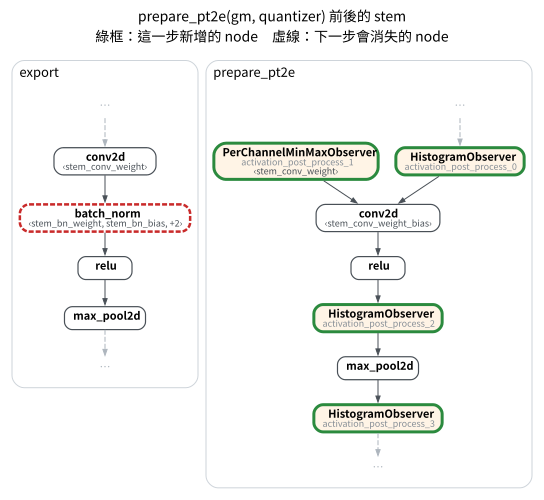

In [6]:
draw_stages([(gm, "export"), (prepared, "prepare_pt2e")], focus=STEM, hops=0,
             title="prepare_pt2e(gm, quantizer) 前後的 stem")

observer 只觀察、不改數值，所以 prepare 之後的圖和原模型輸出幾乎一樣。
唯一的差異來自 BN 折進 conv 時的浮點運算順序。
（對複製的圖做比較：直接呼叫 `prepared` 的話，observer 會把這筆輸入也記進校準統計。）

In [7]:
with torch.no_grad():
    s = sqnr(model(*ex), copy.deepcopy(prepared)(*ex))
print(f"prepare 後的圖 vs fp32 模型：SQNR = {s:.1f} dB")
assert not any(short(n.target) == "batch_norm" for n in prepared.graph.nodes)
assert s > 100

prepare 後的圖 vs fp32 模型：SQNR = 125.8 dB


## 3. calibrate：讓 observer 看資料

直接把資料餵給 prepare 之後的圖。每個 observer 記下自己那條邊上看過的數值範圍，
之後用 `calculate_qparams()` 換算成 scale 和 zero point（公式見本章概覽）。

In [8]:
with torch.no_grad():
    for batch in calibration_batches(n=256, batch_size=32):
        prepared(*batch)

rows = []
for node, obs in observer_nodes(prepared)[:5]:
    scale, zp = obs.calculate_qparams()
    kind = f"per-channel，{scale.numel()} 組" if scale.numel() > 1 else "per-tensor"
    rows.append([node.name, type(obs).__name__, kind, f"{float(scale.flatten()[0]):.5f}", int(zp.flatten()[0])])
table(rows, ["observer", "型別", "粒度", "scale（第一組）", "zero point"])

observer,型別,粒度,scale（第一組）,zero point
activation_post_process_1,PerChannelMinMaxObserver,per-channel，16 組,0.00244,0
activation_post_process_4,PerChannelMinMaxObserver,per-channel，16 組,0.00333,0
activation_post_process_6,PerChannelMinMaxObserver,per-channel，16 組,0.00228,0
activation_post_process_10,PerChannelMinMaxObserver,per-channel，32 組,0.00195,0
activation_post_process_14,PerChannelMinMaxObserver,per-channel，4 組,0.00821,0


## 4. convert：observer → quantize / dequantize

`convert_pt2e` 用每個 observer 算出的 qparams，把它換成一對 `quantize_per_tensor` → `dequantize_per_tensor`。
weight 那邊則直接存成 int8 常數，前面只剩一個 `dequantize_per_channel`。
`convert_pt2e` 也會原地修改，同樣先複製一份。

這次 `hops=1`，把 stem 前後相鄰的 observer 也畫進來。左邊 prepare 的圖裡，虛線框的 observer 在 convert 之後消失；
右邊綠框的 q/dq 就是取代它們的 node，上面的 scale／zp 和左邊 observer 算出的相同。

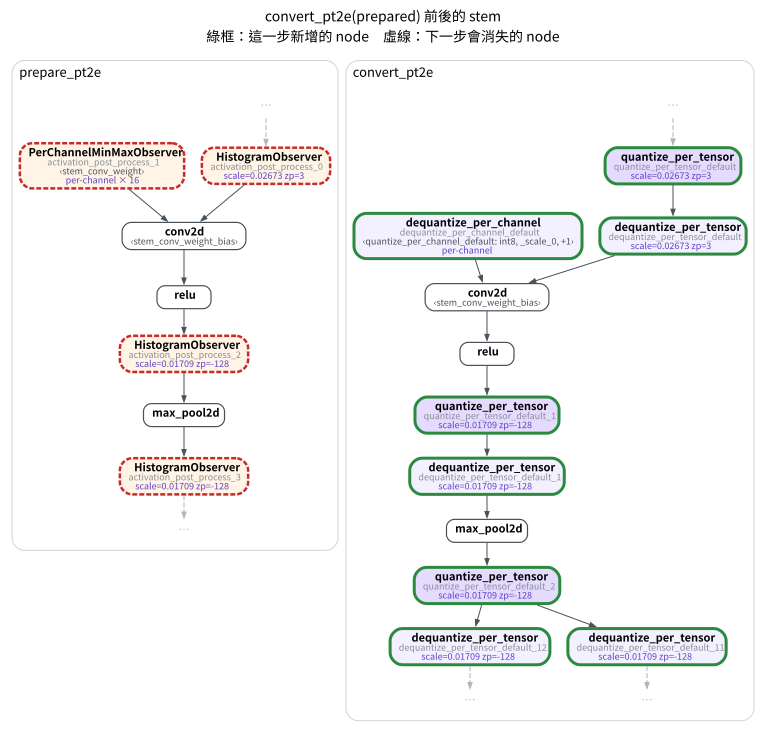

In [9]:
quantized = convert_pt2e(copy.deepcopy(prepared))
draw_stages([(prepared, "prepare_pt2e"), (quantized, "convert_pt2e")], focus=STEM, hops=1,
            title="convert_pt2e(prepared) 前後的 stem")

In [10]:
assert not observer_nodes(quantized)
print(f"q/dq node 數量：{len(qdq_nodes(quantized))}")

q/dq node 數量：28


## 驗收：精度掉了多少

SQNR（signal-to-quantization-noise ratio）把「和 fp32 輸出差多少」換成 dB，越大越接近。

In [11]:
acc_int8 = evaluate(quantized, test_loader)
stats = compare(model, quantized, ex)
table([
    ["accuracy", f"{acc_fp32:.4f}", f"{acc_int8:.4f}"],
    ["輸出 SQNR（對 fp32）", "-", f"{stats['sqnr_db']:.1f} dB"],
    ["最大絕對誤差", "-", f"{stats['max_abs_err']:.4f}"],
], ["", "fp32 模型", "convert 後的圖"])

,fp32 模型,convert 後的圖
accuracy,0.8828,0.8828
輸出 SQNR（對 fp32）,-,30.3 dB
最大絕對誤差,-,0.1175


## 小結

- 四步驟裡只有 prepare 和 convert 會改圖；quantizer 只負責標註。
- convert 之後的圖叫 **Q/DQ 圖**：每個 op 前後包著 q/dq，但 conv、relu 本身仍然是 fp32 運算。
  它在數值上模擬了 int8，並不會比較快。真正換成 int8 kernel 要交給後端（M07 起）。
- 下一本 M01-2 把 prepare 與 convert 對圖的改動逐一攤開來看。